# PROGETTO 3
# 1. Data Exploration & Pre-Processing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [6]:
# caricamento e analisi dei dati
data = load_wine(as_frame=True)
X, y = data.data, data.target

print("Shape:", X.shape)
print("\nTipi di dato:")
display(X.dtypes)          
display(X.describe())       # statistiche descrittive
display(y.value_counts())   # distribuzione delle classi

Shape: (178, 13)

Tipi di dato:


alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
dtype: object

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


target
1    71
0    59
2    48
Name: count, dtype: int64

In [ ]:
# standardizzazione 
scaler = StandardScaler()
X_std = scaler.fit_transform(X)

X_std_df = pd.DataFrame(X_std, columns=X.columns)   # converto in df per migliore leggibilità e avere media e std per ogni colonna
print("Media:\n", X_std_df.mean().round(2))
print("\nStd:\n", X_std_df.std().round(2))

Media:
 alcohol                        -0.0
malic_acid                     -0.0
ash                            -0.0
alcalinity_of_ash              -0.0
magnesium                      -0.0
total_phenols                   0.0
flavanoids                     -0.0
nonflavanoid_phenols            0.0
proanthocyanins                -0.0
color_intensity                 0.0
hue                             0.0
od280/od315_of_diluted_wines    0.0
proline                        -0.0
dtype: float64

Std:
 alcohol                         1.0
malic_acid                      1.0
ash                             1.0
alcalinity_of_ash               1.0
magnesium                       1.0
total_phenols                   1.0
flavanoids                      1.0
nonflavanoid_phenols            1.0
proanthocyanins                 1.0
color_intensity                 1.0
hue                             1.0
od280/od315_of_diluted_wines    1.0
proline                         1.0
dtype: float64


# 2. Data Dimensionality Reduction

In [ ]:
# data reduction 2D con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)
print("Shape X_pca:", X_pca.shape)
display(X_pca)

# Varianza spiegata
print("\nVarianza spiegata per componente:", pca.explained_variance_ratio_.round(4))
print("Varianza totale spiegata:", pca.explained_variance_ratio_.sum().round(4))

# Le 2 componenti (PC1 e PC2) catturano circa il 55% della varianza originale

Shape X_pca: (178, 2)


array([[ 3.31675081,  1.44346263],
       [ 2.20946492, -0.33339289],
       [ 2.51674015,  1.0311513 ],
       [ 3.75706561,  2.75637191],
       [ 1.00890849,  0.86983082],
       [ 3.05025392,  2.12240111],
       [ 2.44908967,  1.17485013],
       [ 2.05943687,  1.60896307],
       [ 2.5108743 ,  0.91807096],
       [ 2.75362819,  0.78943767],
       [ 3.47973668,  1.30233324],
       [ 1.7547529 ,  0.61197723],
       [ 2.11346234,  0.67570634],
       [ 3.45815682,  1.13062988],
       [ 4.31278391,  2.09597558],
       [ 2.3051882 ,  1.66255173],
       [ 2.17195527,  2.32730534],
       [ 1.89897118,  1.63136888],
       [ 3.54198508,  2.51834367],
       [ 2.0845222 ,  1.06113799],
       [ 3.12440254,  0.78689711],
       [ 1.08657007,  0.24174355],
       [ 2.53522408, -0.09184062],
       [ 1.64498834, -0.51627893],
       [ 1.76157587, -0.31714893],
       [ 0.9900791 ,  0.94066734],
       [ 1.77527763,  0.68617513],
       [ 1.23542396, -0.08980704],
       [ 2.18840633,


Varianza spiegata per componente: [0.362  0.1921]
Varianza totale spiegata: 0.5541


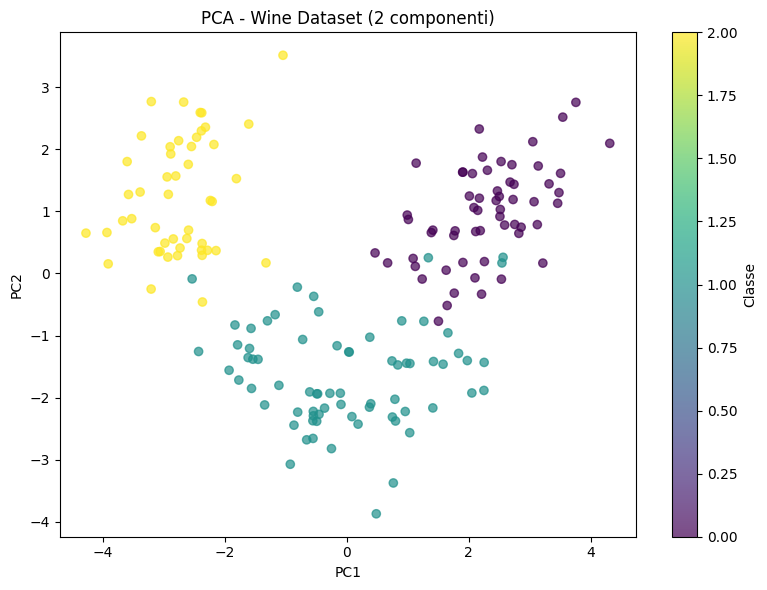

In [ ]:
# rappresentazione grafica dei dati standardizzati per ciascuna classe di y (0, 1 e 2)
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis', alpha=0.7)
plt.colorbar(label='Classe')
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Wine Dataset (2 componenti)")
plt.tight_layout()
plt.show()

# 3. Addestramento & Valutazione

In [24]:
# allenaimo il modello di classificazione K_NN (K-Nearest-Neighbors) con k=5 (valore sempre dispari) sul dataset ridotto a 2 componenti
k = 5
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X_pca, y)
y_pred_knn = knn.predict(X_pca)


# calcolo accuratezza
tot_samples = len(y)

correct_arr = (y_pred_knn == y )
correct_count = np.sum(correct_arr)
incorrect_count = tot_samples - correct_count
print(f"TOT:\t{tot_samples}")
print(f"Corretti K_NN:\t{correct_count}")
print(f"Incorretti K_NN:\t{incorrect_count}")

print(f"ACCURACY KNN: {accuracy_score(y, y_pred_knn) * 100:.2f}%")

TOT:	178
Corretti K_NN:	172
Incorretti K_NN:	6
ACCURACY KNN: 96.63%


In [ ]:
# alleniamo il modello di classificazione SVM (Support Vector Machine) con un kernell lineare sul dataset ridotto a 2 componenti
svc_linear = SVC(kernel="linear", C=1.0, random_state=42)   
# C=tolleranza errori (grande:penalizzazione errori (rischio overfitting)-piccolo:tollera più errori (rischio underfitting))
svc_linear.fit(X_pca, y)
y_pred_linear = svc_linear.predict(X_pca)


# calcolo accuratezza
tot_samples = len(y)

correct_lin = np.sum(y_pred_linear == y)
incorrect_lin = tot_samples - correct_lin
print(f"TOT:\t{tot_samples}")
print(f"Corretti SVM:\t{correct_lin}")
print(f"Incorretti SVM:\t{incorrect_lin}")

print(f"ACCURACY SVM: {accuracy_score(y, y_pred_linear) * 100:.2f}%")

# l'accuratezza è paragonabile tra i 2 modelli di classificazione
# l'accuracy è calcolata sull'intero set di dati ridotto, coincidente con il training set. 
# I valori elevati (KNN: 96.6%, SVM: 97%) sono quindi da attribuire parzialmente all'assenza di una separazione train/test

TOT:	178
Corretti SVM:	173
Incorretti SVM:	5
ACCURACY SVM: 97.19%


# 4. Analisi & Visualizzazione

In [27]:
# individuazione dei confini di decisione (decision boundary)
# imposto i limiti del piano cartesiano (valori min e max di PC1 e PC2) con margine di 0.5
x_min, x_max = X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5    
y_min, y_max = X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5

# creo con meshgrid una griglia rettangolare in cui i punti saranno equispaziati di 0.02 (con arange)
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02))  

# facciamo le predizione della label, per K_NN e SVM, a partire dalle coordinate individuate con la meshgrid ma appiattite con ravel (da matrice 2D a vettore 1D)
# np.c_ unisce le coordinate colonna per colonna ( [x1, y1], [x2, y2], [x3, y3]....)
Z_knn = knn.predict(np.c_[xx.ravel(), yy.ravel()])
Z_knn = Z_knn.reshape(xx.shape)   # riportiamo le coordinate nella forma originale (quindi da vettore 1D a matrice 2D)

Z_linear = svc_linear.predict(np.c_[xx.ravel(), yy.ravel()])
Z_linear = Z_linear.reshape(xx.shape)  # da vettore 1D a matrice 2D


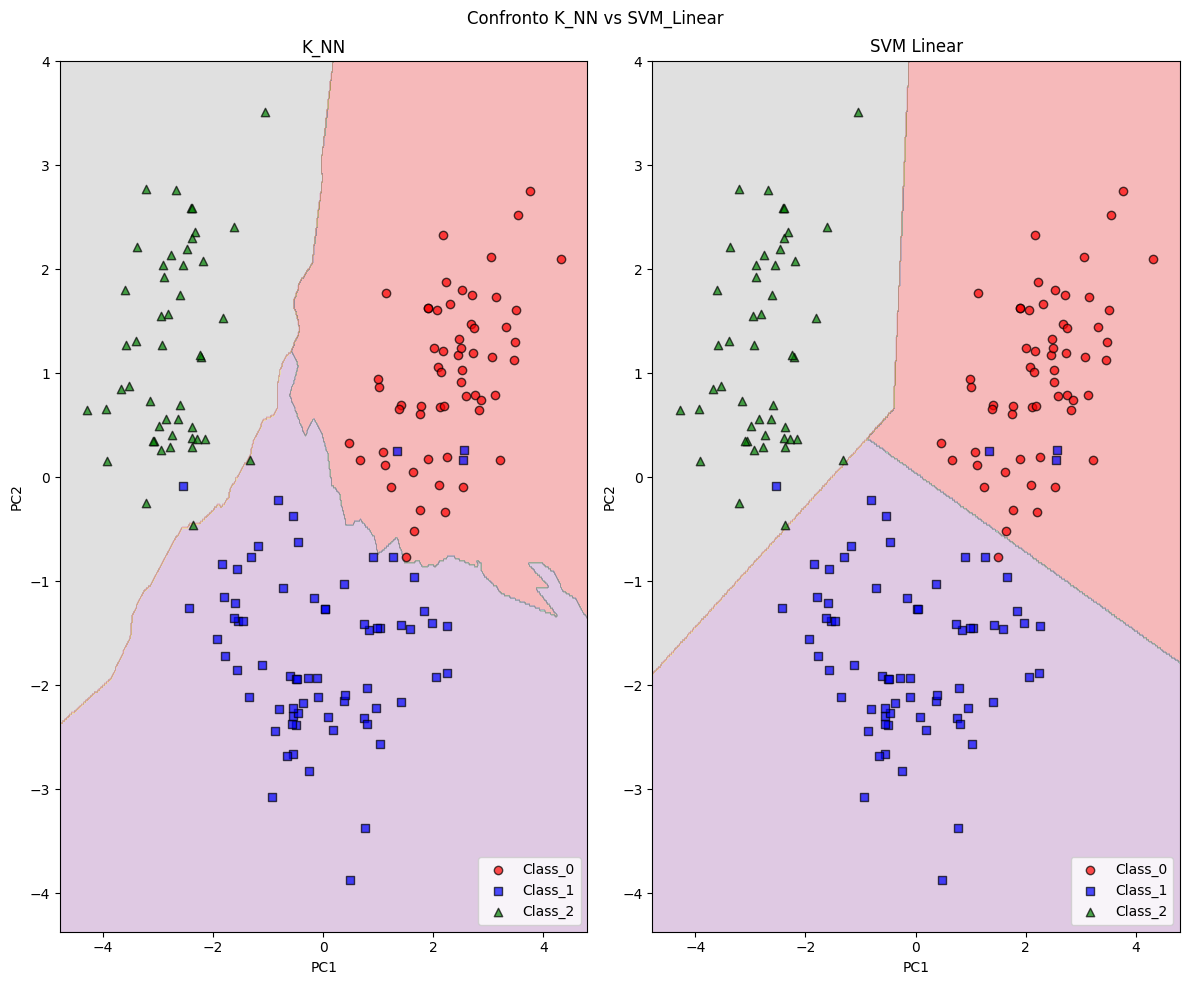

In [31]:
# plot
plt.figure(figsize=(12, 10))
plt.suptitle("Confronto K_NN vs SVM_Linear")

plt.subplot(1, 2, 1)   # 1° grafico
plt.contourf(xx, yy, Z_knn, alpha=0.3, cmap=plt.cm.Set1)   # conturf per colorare il decision boundary + cmap=colormap(cm) di matplotlib(plt) con palette Set1
plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c="red", edgecolors="k", marker="o", label = "Class_0", alpha= 0.7)  
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c="blue", edgecolors="k", marker="s", label = "Class_1", alpha= 0.7)  
plt.scatter(X_pca[y == 2, 0], X_pca[y == 2, 1], c="green", edgecolors="k", marker="^", label="Class_2", alpha=0.7)
plt.title("K_NN")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(loc="lower right")

plt.subplot(1, 2, 2)   # 2° grafico
plt.contourf(xx, yy, Z_linear, alpha=0.3, cmap=plt.cm.Set1)  
plt.scatter(X_pca[y == 0, 0], X_pca[y == 0, 1], c="red", edgecolors="k", marker="o", label = "Class_0", alpha= 0.7)  
plt.scatter(X_pca[y == 1, 0], X_pca[y == 1, 1], c="blue", edgecolors="k", marker="s", label = "Class_1", alpha= 0.7)  
plt.scatter(X_pca[y == 2, 0], X_pca[y == 2, 1], c="green", edgecolors="k", marker="^", label="Class_2", alpha=0.7) 
plt.title("SVM Linear")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()

# entrambi i modelli approssimano abbastanza bene, i punti reali sono ben inseriti nelle regioni predette 